# __Appendix A__

## Signature Assignment 8: Compose an Academic Paper for a Data Science Study
### Comparing GAM vs SARIMAX and Direct GAM vs Recursive GAM to forecast PIC deaths

Dawud Ujamaa  
School of Technology & Engineering, National University  
DDS-7255: Advanced Research Design in Data Science  
Dr. Seyedmohsen Hosseini  
October 18, 2026

In [1]:
import time
import warnings
warnings.filterwarnings("ignore")
from IPython.display import Markdown

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.linear_model import LassoCV
from sklearn.model_selection import TimeSeriesSplit

from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.stattools import acf
from statsmodels.tsa.stattools import pacf
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.graphics.tsaplots import plot_pacf
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import ccf
from pmdarima.arima import ADFTest
import pmdarima as pm

from pygam import PoissonGAM, s, l

from scipy.stats import norm
from dieboldmariano import dm_test

from sklearn.preprocessing import StandardScaler

start_time = time.time()
print(f"Notebook started at: {time.strftime('%Y-%m-%d %H:%M:%S', time.localtime(start_time))}")

Notebook started at: 2026-10-18 20:39:32


### __1: Business Understanding__ 

#### __Problem Statement__
The ability to forecast deaths related to respiratory viruses such as Pneumonia, Influenza, and COVID-19 (PIC) helps healthcare professionals and public health workers prepare timely responses to mitigate the adverse impacts of these events. While previous studies have used models like ARIMA and GAM to forecast Pneumonia, Influenza, and/or COVID-19 incidence and hospitalizations, there have been no studies focused on forecasting PIC deaths. As a result, this gap in the research leaves healthcare professionals and public health workers unprepared in times of crisis. 
The most useful forecasts are those which are able to make predictions further into the future while still maintaining some level of accuracy. Multi-step forecasting strategies are a class of methods used with forecasting models to make predictions multiple steps into the future. Previous studies have investigated the effectiveness of Direct and Recursive multi-step forecasting strategies on ARIMA models, but there have been no studies that have investigated the effectiveness of Direct and Recursive multi-step forecasting strategies on GAM models. This additional GAP in the literature brings into question the reliability and effectiveness of the multi-step forecasting strategies selected for GAM models in previous studies focused on forecasting respiratory viruses.
The two aforementioned gaps in the literature present an opportunity to conduct data science research to evaluate and compare the accuracy of ARIMA and GAM models used to forecast PIC deaths, and to evaluate and compare the accuracy of Direct and Recursive multi-step forecasting strategies on GAM models used to forecast PIC deaths. The potential consequence of leaving these problems unaddressed results in healthcare professionals and public health workers being unequipped with accurate models to forecast PIC deaths in times of crisis. 

#### __Purpose Statement__
The purpose of this research is to: (a) compare and evaluate the performance and accuracy of ARIMA and GAM models used to forecast PIC deaths; and (b) compare and evaluate the performance and accuracy of Direct and Recursive multi-step forecasting strategies on GAM models used to forecast PIC deaths. This is a quantitative comparative predictive research study which will perform statistical hypothesis testing to determine if there is a difference in the performance of the forecasting models and methods. 
This study will apply methods like ARIMA, GAM, LASSO (least absolute shrinkage and selection operator) regression, Direct multi-step forecasting, and Recursive multi-step forecasting. This study will also use metrics like R2, Root Mean Squared Error (RMSE), Mean Squared Error (MSE), Mean Absolute Error (MAE), and Mean Absolute Scaled Error (MASE) to evaluate the performance and accuracy of the models and methods and perform statistical hypothesis testing to determine if a statistical significance exists in the performance of one model or method over another. By conducting this data science research, this study seeks to identify if GAM or ARIMA models are the perform better at forecasting PIC deaths and also identify if a Direct or Recursive multi-step forecasting strategy performs best for GAM models used to forecast PIC deaths multiple steps into the future. This study aims to use data science research methods to impact the preparedness of healthcare professionals and public health workers through improved forecasting of deaths associated with Pneumonia, Influenza, and COVID-19.

#### __Research Questions__
The following research questions will be investigated in this study using ARIMA and GAM models to forecast PIC deaths and using Direct and Recursive multi-step forecasting strategies with GAM models to forecast PIC deaths.
RQ1 (Research Question 1): To what extent does the predictive accuracy of ARIMA and GAM models differ when forecasting PIC deaths?
H10 (Null Hypothesis 1): There is no significant difference between the predictive accuracy of ARIMA and GAM models forecasting PIC deaths.
H1a (Alternative Hypothesis 1): There is a significant difference between the predictive accuracy of ARIMA and GAM models forecasting PIC deaths.

RQ2 (Research Question 2): To what extent does the predictive accuracy of a GAM model using Direct and Recursive multi-step forecasting strategies differ when forecasting PIC deaths 4-weeks ahead?
H20 (Null Hypothesis 2): There is no significant difference between the predictive accuracy of GAM models using Direct and Recursive multi-step forecasting strategies to forecast PIC deaths 4-weeks ahead.
H2a (Alternative Hypothesis 2): There is a significant difference between the predictive accuracy of GAM models using Direct and Recursive multi-step forecasting strategies to forecast PIC deaths 4-weeks ahead.


### __2: Data Understanding - Exploratory Data Analysis (EDA) and Preprocessing__ 
The Kaggle Dataset selected for this assignment is the "US COVID-19 Pneumonia & Flu Deaths Data" dataset downloaded on 09/07/2026 from:
https://www.kaggle.com/datasets/razanihababdellatif/us-covid-19-pneumonia-and-flu-deaths-data

In [2]:
# import data
PIC = pd.read_csv(r"./data/covid_pneumonia_flu_deaths_us.csv", parse_dates=['Week Ending Date'])
PIC

,Data as of,Start Date,End Date,Group,Year,Month,MMWR Week,Week Ending Date,State,COVID-19 Deaths,Total Deaths,Percent of Expected Deaths,Pneumonia Deaths,Pneumonia and COVID-19 Deaths,Influenza Deaths,"Pneumonia, Influenza, or COVID-19 Deaths",Footnote
0,07/30/2026,12/29/2019,01/04/2020,By Week,2019/2020,NaN,1.0,2020-01-04,United States,0,"60,170",98.0,"4,111",0,434,"4,545",NaN
1,07/30/2026,01/05/2020,01/11/2020,By Week,2020,NaN,2.0,2020-01-11,United States,1,"60,734",97.0,"4,153",1,475,"4,628",NaN
2,07/30/2026,01/12/2020,01/18/2020,By Week,2020,NaN,3.0,2020-01-18,United States,2,"59,362",98.0,"4,066",2,468,"4,534",NaN
3,07/30/2026,01/19/2020,01/25/2020,By Week,2020,NaN,4.0,2020-01-25,United States,3,"59,162",99.0,"3,915",0,500,"4,418",NaN
4,07/30/2026,01/26/2020,02/01/2020,By Week,2020,NaN,5.0,2020-02-01,United States,0,"58,834",99.0,"3,818",0,481,"4,299",NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
23215,07/30/2026,01/01/2020,07/25/2026,By Total,NaN,NaN,NaN,NaT,Washington,"16,914","434,120",NaN,"29,860","9,627","1,471","38,570",NaN
23216,07/30/2026,01/01/2020,07/25/2026,By Total,NaN,NaN,NaN,NaT,West Virginia,"9,170","167,426",NaN,"16,183","4,622",566,"21,274",NaN
23217,07/30/2026,01/01/2020,07/25/2026,By Total,NaN,NaN,NaN,NaT,Wisconsin,"18,805","387,457",NaN,"21,913","6,616","1,195","35,243",NaN
23218,07/30/2026,01/01/2020,07/25/2026,By Total,NaN,NaN,NaN,NaT,Wyoming,"2,044","35,223",NaN,"2,605","1,040",121,"3,724",NaN


In [3]:
# list columns and data types
PIC.dtypes

Data as of                                          object
Start Date                                          object
End Date                                            object
Group                                               object
Year                                                object
Month                                              float64
MMWR Week                                          float64
Week Ending Date                            datetime64[ns]
State                                               object
COVID-19 Deaths                                     object
Total Deaths                                        object
Percent of Expected Deaths                         float64
Pneumonia Deaths                                    object
Pneumonia and COVID-19 Deaths                       object
Influenza Deaths                                    object
Pneumonia, Influenza, or COVID-19 Deaths            object
Footnote                                            obje

In [4]:
# remove commas from string
PIC['Pneumonia, Influenza, or COVID-19 Deaths'] = PIC['Pneumonia, Influenza, or COVID-19 Deaths'].str.replace(',', '', regex=False)

# convert object data type to float
PIC['Pneumonia, Influenza, or COVID-19 Deaths'] = PIC['Pneumonia, Influenza, or COVID-19 Deaths'].astype(float)

**Figure A1**

*Distribution of values in State Variable in Dataset*

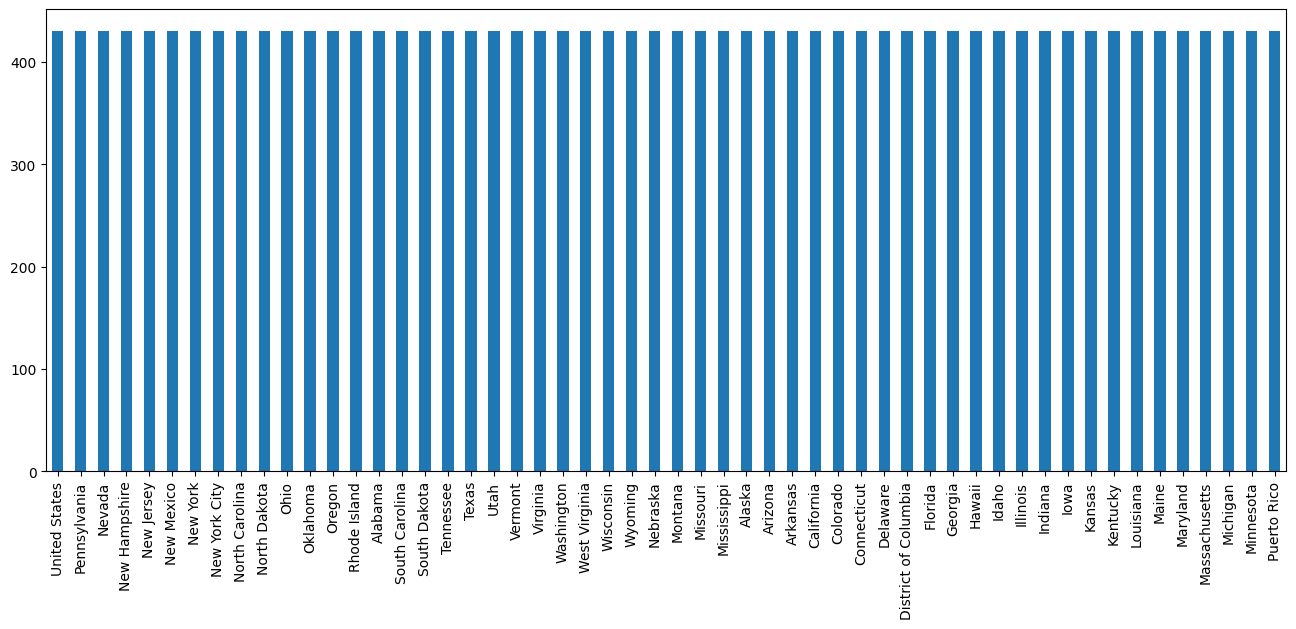

In [5]:
display(Markdown("**Figure A1**"))
display(Markdown("*Distribution of values in State Variable in Dataset*"))

fig1 = plt.figure(figsize=(16, 6))
ax = fig1.add_subplot()
PIC['State'].value_counts().plot(kind='bar');

*Note.* This figure shows a barplot of the Distribution of the State values in the Dataset. 
<div style="page-break-before: always;"></div>

In [6]:
# Values for Group Variable
PIC['Group'].value_counts()

By Week     18522
By Month     4266
By Year       378
By Total       54
Name: Group, dtype: int64

In [7]:
PIC['Week Ending Date'].describe()

count                   18522
unique                    343
top       2020-01-04 00:00:00
freq                       54
first     2020-01-04 00:00:00
last      2026-07-25 00:00:00
Name: Week Ending Date, dtype: object